In [1]:
import pandas as pd
import pickle
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import sklearn
print(sklearn.__version__)
from sklearn.model_selection import ParameterGrid
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    precision_recall_curve,
    auc,
    ConfusionMatrixDisplay
)

1.8.0


In [2]:
# ============================================================
# 1. PARÂMETROS DO MLP
# ============================================================

PARAM_GRID = {
    # Arquitetura da rede
    "hidden_layer_sizes": [
        (32, 16),
        (64, 32),
        (64, 32, 16)
    ],

    # Taxa de aprendizado
    "learning_rate_init": [
        0.0001,
        0.0003,
        0.001
    ],

    # Tamanho do lote
    "batch_size": [
        32,
        64,
        128
    ],

    # Regularização L2
    "alpha": [
        0.0001,
        0.001,
        0.01
    ],

    # Quantidade máxima de épocas
    "max_iter": [
        50,
        100,
        200
    ]
}

# ============================================================
# PARÂMETROS FIXOS
# ============================================================

FIXED_PARAMS = {
    "activation": "relu",
    "solver": "sgd",
    "early_stopping": False,
    "random_state": 42
}

THRESHOLD = 0.25

# ============================================================
# TODAS AS COMBINAÇÕES
# ============================================================

combinacoes = list(
    ParameterGrid(PARAM_GRID)
)

print(
    f"Quantidade de configurações: {len(combinacoes)}"
)

Quantidade de configurações: 243


In [3]:
# ============================================================
# 2. CARREGAMENTO DO DATASET
# ============================================================

arquivo = "C:/Users/gques/Documents/SPTECH_CODIGOS/ultimo-ano/tcc/backend/tabela_final/table_orders_holidays_ecommerce_events.csv"


df = pd.read_csv(arquivo)

In [4]:


target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

# Quantos dias a transportadora tem para entregar apos pegar o pacote?
df['prazo_transportadora_dias'] = (df['order_estimated_delivery_date'] - df['order_delivered_carrier_date']).dt.days

# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['prazo_transportadora_dias']).copy()

# Extraindo o mes da compra (sazonalidade - Black Friday, Natal)
df['carrier_month'] = df['order_delivered_carrier_date'].dt.month

# =====================================================================
# 1b. FEATURES DE INTERAÇÃO (Adicionadas para aumentar o sinal)
# =====================================================================
df['prazo_por_km'] = df['prazo_transportadora_dias'] / (df['distance_km'] + 1)
df['frete_por_kg'] = df['freight_value'] / (df['product_weight_g'] / 1000 + 0.1)
df['densidade_produto'] = df['product_weight_g'] / (df['volume_cm3'] + 1)

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier",
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    # "had_ecommerce_event_14_days_ago",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",
    "customer_city",
    "seller_city",
    "category_name"
]

X = X.drop(columns=colunas_remover, errors='ignore')

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()


# ============================================================
# 10. HOLD-OUT TEMPORAL PARA BUSCA DE HIPERPARÂMETROS
# ============================================================

# Data de corte entre treinamento e validação.
# Treinamento: até abril/2018.
# Validação: maio e junho/2018.

val_split_date = pd.to_datetime("2018-05-01", utc=True)

carrier_train_dates = pd.to_datetime(
    df.loc[X_train.index, "order_delivered_carrier_date"],
    utc=True
)

customer_train_dates = pd.to_datetime(
    df.loc[X_train.index, "order_delivered_customer_date"],
    utc=True
)

# Identificação do treinamento e validação.
tr_mask_tune = (
    (carrier_train_dates < val_split_date) &
    (customer_train_dates < val_split_date)
)

va_mask_tune = (
    carrier_train_dates >= val_split_date
)

# Identificação dos registros que serão expurgados.
n_expurgados_val = int(
    (
        (carrier_train_dates < val_split_date) &
        (customer_train_dates >= val_split_date)
    ).sum()
)

# Remove os registros que atravessam a fronteira temporal.
train_clean_mask = tr_mask_tune | va_mask_tune

X_train = X_train.loc[train_clean_mask].copy()
y_train = y_train.loc[train_clean_mask].copy()

carrier_train_dates = carrier_train_dates.loc[train_clean_mask]
customer_train_dates = customer_train_dates.loc[train_clean_mask]

# Índices dos conjuntos.
tr_idx = np.where(
    (carrier_train_dates < val_split_date).values
)[0]

va_idx = np.where(
    (carrier_train_dates >= val_split_date).values
)[0]

# Separação dos conjuntos.
X_treino_busca = X_train.iloc[tr_idx].copy()
y_treino_busca = y_train.iloc[tr_idx].copy()

X_validacao = X_train.iloc[va_idx].copy()
y_validacao = y_train.iloc[va_idx].copy()

# Normalização sem vazamento de dados.
scaler_busca = StandardScaler()

X_treino_busca = pd.DataFrame(
    scaler_busca.fit_transform(X_treino_busca),
    columns=X_train.columns,
    index=X_treino_busca.index
)

X_validacao = pd.DataFrame(
    scaler_busca.transform(X_validacao),
    columns=X_train.columns,
    index=X_validacao.index
)

# Estatísticas.
qtd_tr_tune = len(X_treino_busca)
qtd_va_tune = len(X_validacao)
qtd_treino = len(X_train)
qtd_teste = len(X_test)

total_linhas = len(X)

pos_count = int((y_train == 1).sum())
atrasos_tr_tune = int((y_treino_busca == 1).sum())
atrasos_va_tune = int((y_validacao == 1).sum())

carrier_test_dates = pd.to_datetime(
    df.loc[X_test.index, "order_delivered_carrier_date"],
    utc=True
)

print("=" * 100)
print("DISTRIBUIÇÃO DOS DADOS - HOLD-OUT TEMPORAL")
print("=" * 100)

print(f"Total de registros: {total_linhas:,}\n")

print("1. SEPARAÇÃO GERAL")
print("-" * 100)

print(f"Treino completo: {qtd_treino:,}")
print(
    f"Atrasos: {pos_count:,} "
    f"({pos_count/qtd_treino:.2%})"
)

print(f"Teste independente: {qtd_teste:,}")
print(
    f"Atrasos: {(y_test == 1).sum():,} "
    f"({(y_test == 1).mean():.2%})\n"
)

print("2. HOLD-OUT TEMPORAL")
print("-" * 100)

print(f"Treino de tuning: {qtd_tr_tune:,}")
print(
    f"Período: {carrier_train_dates.iloc[tr_idx].min():%d/%m/%Y} "
    f"a {carrier_train_dates.iloc[tr_idx].max():%d/%m/%Y}"
)
print(
    f"Atrasos: {atrasos_tr_tune:,} "
    f"({atrasos_tr_tune/qtd_tr_tune:.2%})"
)

print(f"Pedidos expurgados: {n_expurgados_val:,}\n")

print(f"Validação: {qtd_va_tune:,}")
print(
    f"Período: {carrier_train_dates.iloc[va_idx].min():%d/%m/%Y} "
    f"a {carrier_train_dates.iloc[va_idx].max():%d/%m/%Y}"
)
print(
    f"Atrasos: {atrasos_va_tune:,} "
    f"({atrasos_va_tune/qtd_va_tune:.2%})"
)

print("=" * 100)

X_test.head()


DISTRIBUIÇÃO DOS DADOS - HOLD-OUT TEMPORAL
Total de registros: 33,820

1. SEPARAÇÃO GERAL
----------------------------------------------------------------------------------------------------
Treino completo: 28,388
Atrasos: 1,405 (4.95%)
Teste independente: 5,114
Atrasos: 613 (11.99%)

2. HOLD-OUT TEMPORAL
----------------------------------------------------------------------------------------------------
Treino de tuning: 23,296
Período: 08/10/2016 a 27/04/2018
Atrasos: 1,226 (5.26%)
Pedidos expurgados: 318

Validação: 5,092
Período: 02/05/2018 a 29/06/2018
Atrasos: 179 (3.52%)


,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,purchase_hour,purchase_day_of_week,price,freight_value,product_weight_g,volume_cm3,distance_km,same_city,prazo_transportadora_dias,carrier_month,prazo_por_km,frete_por_kg,densidade_produto
28706,0,32,7,15,5,58.99,13.07,200,3960.0,65.936,0,16,7,0.239034,43.566667,0.050492
28707,0,32,7,20,5,24.99,13.76,2350,10648.0,411.255,0,16,7,0.038811,5.616327,0.220678
28708,0,32,7,10,6,119.90,13.50,459,3276.0,284.778,0,20,7,0.069984,24.150268,0.140067
28709,0,32,7,8,6,49.00,13.00,250,640.0,221.179,0,17,7,0.076515,37.142857,0.390016
28710,0,32,7,14,5,106.00,17.95,3305,35100.0,112.930,0,10,7,0.087773,5.271659,0.094157


In [5]:



# ============================================================
# 11. TESTE DE TODAS AS CONFIGURAÇÕES
# ============================================================

resultados = []

total_configuracoes = len(combinacoes)

print("\n" + "=" * 70)
print("INICIANDO BUSCA DE HIPERPARÂMETROS")
print("=" * 70)

print(f"Total de configurações: {total_configuracoes}")

for numero, parametros in enumerate(combinacoes, start=1):

    print(
        f"\n[{numero}/{total_configuracoes}] "
        f"Testando: {parametros}"
    )

    mlp_teste = MLPClassifier(
        **FIXED_PARAMS,
        **parametros
    )

    mlp_teste.fit(
        X_treino_busca,
        y_treino_busca
    )

    # ========================================================
    # PREDIÇÃO NA VALIDAÇÃO
    # ========================================================

    y_prob_validacao = mlp_teste.predict_proba(
        X_validacao
    )[:, 1]

    y_pred_validacao = (
        y_prob_validacao >= THRESHOLD
    ).astype(int)

    # ========================================================
    # MÉTRICAS
    # ========================================================

    accuracy = accuracy_score(
        y_validacao,
        y_pred_validacao
    )

    precision = precision_score(
        y_validacao,
        y_pred_validacao,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_validacao,
        y_pred_validacao,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_validacao,
        y_pred_validacao,
        pos_label=1,
        zero_division=0
    )

    f2 = fbeta_score(
        y_validacao,
        y_pred_validacao,
        beta=2,
        pos_label=1,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_validacao,
        y_prob_validacao
    )

    precision_pr, recall_pr, _ = precision_recall_curve(
        y_validacao,
        y_prob_validacao,
        pos_label=1
    )

    pr_auc = auc(
        recall_pr,
        precision_pr
    )

    # ========================================================
    # SALVA RESULTADO
    # ========================================================

    resultado = {
        **parametros,

        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f2": f2,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,

        "epocas_executadas": mlp_teste.n_iter_
    }

    resultados.append(resultado)

    print(
        f"F2: {f2:.4f} | "
        f"Recall: {recall:.4f} | "
        f"Precision: {precision:.4f} | "
        f"PR-AUC: {pr_auc:.4f} | "
        f"Épocas: {mlp_teste.n_iter_}"
    )


# ============================================================
# 11.1 RANKING DAS CONFIGURAÇÕES
# ============================================================

resultados_df = pd.DataFrame(
    resultados
)

# Precision mínima desejada para a classe atraso
PRECISION_MINIMA = 0.10

# Mantém apenas as configurações que atingiram
# a precisão mínima
resultados_filtrados = resultados_df[
    resultados_df["precision"] >= PRECISION_MINIMA
].copy()

if len(resultados_filtrados) == 0:

    print(
        "\nNenhuma configuração atingiu "
        f"Precision >= {PRECISION_MINIMA:.2f}."
    )

    raise ValueError(
        "Aumente o número de combinações ou "
        "reduza a PRECISION_MINIMA."
    )

else:

    # Prioridade:
    # 1. maior Recall
    # 2. maior F2
    # 3. maior PR-AUC

    resultados_filtrados = resultados_filtrados.sort_values(
        by=["pr_auc"],
        ascending=False
    ).reset_index(drop=True)

    melhor_resultado = resultados_filtrados.iloc[0]

    print("\n" + "=" * 70)
    print("MELHORES CONFIGURAÇÕES")
    print("=" * 70)

    display(
        resultados_filtrados.head(10)
    )

# ============================================================
# 11.2 MELHOR CONFIGURAÇÃO
# ============================================================

# Usa a melhor configuração entre as que passaram no critério de precisão.
# Não usar resultados_df.iloc[0]: ele apenas pega a primeira combinação testada.
melhor_resultado = resultados_filtrados.iloc[0]

BEST_PARAMS = {
    "hidden_layer_sizes": melhor_resultado["hidden_layer_sizes"],
    "learning_rate_init": melhor_resultado["learning_rate_init"],
    "batch_size": int(melhor_resultado["batch_size"]),
    "alpha": melhor_resultado["alpha"],
    "max_iter": int(melhor_resultado["max_iter"])
}

MLP_PARAMS = {
    **FIXED_PARAMS,
    **BEST_PARAMS
}

print("\n" + "=" * 70)
print("MELHOR CONFIGURAÇÃO ENCONTRADA")
print("=" * 70)

print(f"Arquitetura:       {BEST_PARAMS['hidden_layer_sizes']}")
print(f"Learning rate:     {BEST_PARAMS['learning_rate_init']}")
print(f"Batch size:        {BEST_PARAMS['batch_size']}")
print(f"Alpha:             {BEST_PARAMS['alpha']}")
print(f"Max iter:          {BEST_PARAMS['max_iter']}")

print("\nParâmetros fixos:")
print(f"Activation:        {FIXED_PARAMS['activation']}")
print(f"Solver:            {FIXED_PARAMS['solver']}")

print("\nResultado na validação:")
print(f"Accuracy:           {melhor_resultado['accuracy']:.4f}")
print(f"Precision:          {melhor_resultado['precision']:.4f}")
print(f"Recall:             {melhor_resultado['recall']:.4f}")
print(f"F1:                 {melhor_resultado['f1']:.4f}")
print(f"F2:                 {melhor_resultado['f2']:.4f}")
print(f"ROC-AUC:            {melhor_resultado['roc_auc']:.4f}")
print(f"PR-AUC:             {melhor_resultado['pr_auc']:.4f}")



# ============================================================
# 11.3 TREINAMENTO FINAL COM A MELHOR CONFIGURAÇÃO
# ============================================================

print("\n" + "=" * 70)
print("TREINAMENTO FINAL")
print("=" * 70)

# Novo scaler ajustado com todo o treinamento.
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Treinamento final.
mlp = MLPClassifier(
    **MLP_PARAMS
)

mlp.fit(
    X_train_scaled,
    y_train
)

print(
    f"Épocas executadas no modelo final: {mlp.n_iter_}"
)



# ============================================================
# 11.4 SALVAMENTO DO MODELO FINAL
# ============================================================

# O modelo recebe 26 variáveis numéricas, mas a API recebe os campos brutos
# do formulário/CSV. Por isso, o artefato precisa carregar também os mapas
# de target encoding criados SOMENTE com o conjunto de treino.

raw_columns = [
    "purchase_date",
    "purchase_time",
    "carrier_datetime",
    "estimated_delivery_datetime",
    "price",
    "freight_value",
    "product_weight_g",
    "height_cm",
    "width_cm",
    "length_cm",
    "distance_km",
    "same_city"
]

modelo = {
    # Objetos necessários para a inferência
    "model": mlp,
    "scaler": scaler,
    "features": X_train.columns.tolist(),
    "feature_names": X_train.columns.tolist(),
    "threshold": float(THRESHOLD),
    "params": MLP_PARAMS,

    # Dados necessários para repetir o pré-processamento da API
    "raw_columns": raw_columns,
    "inference_moment": "carrier_collection",
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],

    # Contrato do artefato consumido pela API
    "schema_version": 3,
    "model_type": "MLPClassifier",
    "model_name": "MLP (Rede Neural)",
}

caminho_modelo = Path.cwd() / "modelo_mlp_final.pkl"

with open(
    caminho_modelo,
    "wb"
) as arquivo:

    pickle.dump(
        modelo,
        arquivo,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print(
    f"\nModelo final salvo com sucesso em: "
    f"{caminho_modelo}"
)
print(f"Variáveis do modelo: {len(modelo['features'])}")
print(f"Limiar de atraso: {modelo['threshold']:.2f}")


# ============================================================
# 11.2 GRÁFICOS DE TREINAMENTO E VALIDAÇÃO
# ============================================================

epocas = range(1, len(mlp.loss_curve_) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1 - Perda do treinamento
axes[0].plot(
    epocas,
    mlp.loss_curve_,
    label="Perda de treinamento",
    color="blue"
)

axes[0].set_title("Curva de perda do treinamento")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Loss")
axes[0].grid(True)
axes[0].legend()

# Gráfico 2 - Acurácia de validação
if mlp.validation_scores_ is not None:
    epocas_validacao = range(
        1,
        len(mlp.validation_scores_) + 1
    )

    axes[1].plot(
        epocas_validacao,
        mlp.validation_scores_,
        label="Acurácia de validação",
        color="green"
    )

    axes[1].set_title("Acurácia de validação por época")
    axes[1].set_xlabel("Épocas")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(True)
    axes[1].legend()

plt.tight_layout()
plt.show()


INICIANDO BUSCA DE HIPERPARÂMETROS
Total de configurações: 243

[1/243] Testando: {'alpha': 0.0001, 'batch_size': 32, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.0001, 'max_iter': 50}


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


F2: 0.2439 | Recall: 0.2123 | Precision: 0.6032 | PR-AUC: 0.3525 | Épocas: 50

[2/243] Testando: {'alpha': 0.0001, 'batch_size': 32, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.0001, 'max_iter': 100}


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


F2: 0.3369 | Recall: 0.3184 | Precision: 0.4385 | PR-AUC: 0.3678 | Épocas: 100

[3/243] Testando: {'alpha': 0.0001, 'batch_size': 32, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.0001, 'max_iter': 200}
F2: 0.3369 | Recall: 0.3184 | Precision: 0.4385 | PR-AUC: 0.3676 | Épocas: 101

[4/243] Testando: {'alpha': 0.0001, 'batch_size': 32, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.0003, 'max_iter': 50}


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


... (139 outputs left out)

c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


F2: 0.3302 | Recall: 0.3128 | Precision: 0.4242 | PR-AUC: 0.3824 | Épocas: 50

[107/243] Testando: {'alpha': 0.001, 'batch_size': 32, 'hidden_layer_sizes': (64, 32, 16), 'learning_rate_init': 0.001, 'max_iter': 100}


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


F2: 0.3293 | Recall: 0.3073 | Precision: 0.4622 | PR-AUC: 0.3684 | Épocas: 100

[108/243] Testando: {'alpha': 0.001, 'batch_size': 32, 'hidden_layer_sizes': (64, 32, 16), 'learning_rate_init': 0.001, 'max_iter': 200}


# Gráfico 01
A curva de perda mostra o erro que o modelo apresenta durante o treinamento.

Curva decrescente: o modelo está aprendendo a ajustar seus pesos.

Curva estabilizada: o treinamento pode ter atingido um platô.

Curva crescente: pode indicar instabilidade ou dificuldades de otimização.

# Gráfico 02

A curva de validação mostra como o modelo classifica as amostras reservadas para validação durante o treinamento.

Acurácia crescente: o modelo está melhorando sua capacidade de classificação no conjunto de validação.

Acurácia estabilizada: pode indicar que o modelo deixou de apresentar melhorias.

Acurácia decrescente: pode indicar que o modelo está perdendo capacidade de generalização.

In [ ]:
# ============================================================
# 12. PREDIÇÃO
# ============================================================

y_prob = mlp.predict_proba(
    X_test_scaled
)[:, 1]

y_pred = (
    y_prob >= THRESHOLD
).astype(int)

In [ ]:
# ============================================================
# 13. MÉTRICAS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision_atraso = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall_atraso = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1_atraso = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f2_atraso = fbeta_score(
    y_test,
    y_pred,
    beta=2,
    pos_label=1,
    zero_division=0
)

roc_auc_atraso = roc_auc_score(
    y_test,
    y_prob
)

precision_pr, recall_pr, _ = precision_recall_curve(
    y_test,
    y_prob,
    pos_label=1
)

pr_auc_atraso = auc(
    recall_pr,
    precision_pr
)


RESULTADOS - MLP
Arquitetura: (32, 16)
Activation: relu
Solver: adam
Learning rate: 0.0001
Batch size: 32
Épocas máximas: 200
Limiar: 0.25

Quantidade de amostras:
Treino: 28388
Teste:  5114

Métricas:
Accuracy:        0.7472
Precision atraso: 0.3053
Recall atraso:    0.8695
F1 atraso:        0.4519
F2 atraso:        0.6348
ROC-AUC atraso:   0.8996
PR-AUC atraso:    0.6822

Como interpretar as métricas:
- Precision atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- Recall atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- F1 atraso: média harmônica entre precision e recall.
- F2 atraso: semelhante ao F1, mas dando mais peso ao recall.
- ROC-AUC atraso: capacidade do modelo de separar atrasos de não atrasos em diferentes limiares.
- PR-AUC atraso: desempenho no equilíbrio entre precision e recall para a classe atraso.


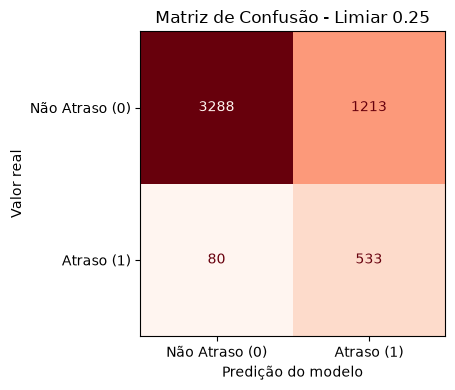


Relatório de classificação:
                precision    recall  f1-score   support

Não Atraso (0)       0.98      0.73      0.84      4501
    Atraso (1)       0.31      0.87      0.45       613

      accuracy                           0.75      5114
     macro avg       0.64      0.80      0.64      5114
  weighted avg       0.90      0.75      0.79      5114


Quantidade de épocas executadas:
136


In [ ]:
# ============================================================
# 14. RESULTADOS
# ============================================================

print("\n" + "=" * 60)
print("RESULTADOS - MLP")
print("=" * 60)

print(f"Arquitetura: {MLP_PARAMS['hidden_layer_sizes']}")
print(f"Activation: {MLP_PARAMS['activation']}")
print(f"Solver: {MLP_PARAMS['solver']}")
print(f"Learning rate: {MLP_PARAMS['learning_rate_init']}")
print(f"Batch size: {MLP_PARAMS['batch_size']}")
print(f"Épocas máximas: {MLP_PARAMS['max_iter']}")
print(f"Limiar: {THRESHOLD:.2f}")

print("\nQuantidade de amostras:")
print(f"Treino: {len(X_train)}")
print(f"Teste:  {len(X_test)}")

print("\nMétricas:")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Precision atraso: {precision_atraso:.4f}")
print(f"Recall atraso:    {recall_atraso:.4f}")
print(f"F1 atraso:        {f1_atraso:.4f}")
print(f"F2 atraso:        {f2_atraso:.4f}")
print(f"ROC-AUC atraso:   {roc_auc_atraso:.4f}")
print(f"PR-AUC atraso:    {pr_auc_atraso:.4f}")

# ============================================================
# INTERPRETAÇÃO DAS MÉTRICAS
# ============================================================

print("\nComo interpretar as métricas:")
print("- Precision atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- Recall atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- F1 atraso: média harmônica entre precision e recall.")
print("- F2 atraso: semelhante ao F1, mas dando mais peso ao recall.")
print("- ROC-AUC atraso: capacidade do modelo de separar atrasos de não atrasos em diferentes limiares.")
print("- PR-AUC atraso: desempenho no equilíbrio entre precision e recall para a classe atraso.")

# ============================================================
# MATRIZ DE CONFUSÃO
# ============================================================

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Reds",
    ax=ax,
    colorbar=False,
    display_labels=[
        "Não Atraso (0)",
        "Atraso (1)"
    ]
)

ax.set_title(
    f"Matriz de Confusão - Limiar {THRESHOLD:.2f}"
)

ax.set_xlabel("Predição do modelo")
ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

# ============================================================
# RELATÓRIO DE CLASSIFICAÇÃO
# ============================================================

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Não Atraso (0)",
            "Atraso (1)"
        ],
        zero_division=0
    )
)

print("\nQuantidade de épocas executadas:")
print(mlp.n_iter_)